# pod_shred_nektar

**Question.** Does SHRED do better, or train faster, when it predicts POD coefficients instead of the full field,
as in masked-shred? And does the loss space matter: the decoded field (as SHRED) or the MinMax-scaled coefficients
(as the paper)?

Setup (`configs/experiment/pod_shred_nektar.yaml`, `docs/protocol.md` row *POD SHRED*): Nektar (u, v), 8 QR probes,
clean training and evaluation, 1000 epochs with default early stopping, seeds 0, 1, 2, CPU with 6 workers. POD basis as
in the paper: per field StandardScaler on the training snapshots, SVD, r = 16 / 32 / 64 modes per field (so 2r outputs),
MinMax per coefficient. Same GRU encoder and 350/400 decoder as SHRED; only the output width changes
(10 000 → 2r).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from get_shredded.model import PODSHRED
from get_shredded.runner import load_arrays, load_config, load_results, output_root, prepare_seed

cfg = load_config(["+experiment=pod_shred_nektar"])
MAIN = output_root(cfg)
SMOKE = output_root(load_config(["+experiment=pod_shred_nektar", "name=pod_shred_nektar_smoke"]))
RUNS = [f"{r.method}__{r.train}" for r in cfg.runs]

def describe(run):
    m = cfg.methods[run.split("__")[0]]
    if m.kind == "shred":
        return "full field", "–", "field"
    return "POD", str(m.rank), str(m.loss_space)

def seed_table(rt, seeds):
    res = load_results(rt)
    rows = ["| run | output | r / field | loss | test err | err u | err v | train err | val checks (≈ epochs) | wall s | params |",
            "|---|---|---:|---|---:|---:|---:|---:|---:|---:|---:|"]
    for run in RUNS:
        done = [res[(run, s)] for s in seeds if (run, s) in res]
        if not done:
            continue
        def ms(f):
            v = [f(x["metrics"]) for x in done]
            return f"{np.mean(v):.4f} ± {np.std(v):.4f}" if len(v) > 1 else f"{v[0]:.4f}"
        checks = np.mean([x["metrics"]["epochs_used"] for x in done])
        wall = np.mean([x["wall_time_s"] for x in done])
        out, r, loss = describe(run)
        rows.append(f"| {run} | {out} | {r} | {loss} | {ms(lambda m: m['clean']['err'])} | "
                    f"{ms(lambda m: m['none_oracle_p0']['err_u'])} | {ms(lambda m: m['none_oracle_p0']['err_v'])} | "
                    f"{ms(lambda m: m['train']['err'])} | {checks:.1f} (≈ {20 * (checks - 1):.0f}) | {wall:.0f} | "
                    f"{done[0]['metrics']['parameters']:,} |")
    return Markdown("\n".join(rows))

## 1. Smoke runs (seed 0, 20 epochs)

Outputs in `outputs/pod_shred_nektar_smoke/` (wave and Nektar). They only show that every run trains and evaluates.

In [2]:
display(seed_table(SMOKE, [0]))

| run | output | r / field | loss | test err | err u | err v | train err | val checks (≈ epochs) | wall s | params |
|---|---|---:|---|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | full field | – | field | 0.0938 | 0.0518 | 0.2740 | 0.0927 | 2.0 (≈ 20) | 2 | 4,213,854 |
| pod_shred__clean | POD | 16 | field | 0.0579 | 0.0260 | 0.1800 | 0.0594 | 2.0 (≈ 20) | 1 | 216,686 |
| pod_shred_r32__clean | POD | 32 | field | 0.0596 | 0.0285 | 0.1825 | 0.0618 | 2.0 (≈ 20) | 2 | 229,518 |
| pod_shred_r64__clean | POD | 64 | field | 0.0622 | 0.0298 | 0.1902 | 0.0635 | 2.0 (≈ 20) | 2 | 255,182 |
| pod_shred_coef_r16__clean | POD | 16 | coef | 0.1000 | 0.0473 | 0.3071 | 0.0977 | 2.0 (≈ 20) | 1 | 216,686 |
| pod_shred_coef_r32__clean | POD | 32 | coef | 0.1838 | 0.0981 | 0.5440 | 0.1924 | 2.0 (≈ 20) | 1 | 229,518 |
| pod_shred_coef_r64__clean | POD | 64 | coef | 0.2455 | 0.1318 | 0.7250 | 0.2490 | 2.0 (≈ 20) | 1 | 255,182 |

## 2. Projection floor

The best test error any rank-r model can reach: test snapshots projected on the seed's training basis (per field
StandardScaler, r modes per field), in the same relative L2 as `err`. SHRED's full field has no such floor.

In [3]:
floor = {}
for seed in cfg.eval.seeds:
    sd = prepare_seed(cfg, seed)
    m = sd.load_X.shape[1]
    for r in (16, 32, 64):
        pod = PODSHRED(1, sd.load_X[sd.train_idx], sd.channels, r, np.ones(m), np.zeros(m),
                       hidden_size=4, hidden_layers=1, l1=2, l2=2)
        truth = torch.tensor(sd.truth)
        with torch.no_grad():
            proj = pod.decode(pod.coefficient_targets(truth)).numpy()
        floor.setdefault(r, []).append(np.linalg.norm(proj - sd.truth) / np.linalg.norm(sd.truth))
display(Markdown("| r / field | projection floor (mean ± std over seeds) |\n|---:|---:|\n" + "\n".join(
    f"| {r} | {np.mean(v):.1e} ± {np.std(v):.1e} |" for r, v in floor.items())))

| r / field | projection floor (mean ± std over seeds) |
|---:|---:|
| 16 | 2.9e-04 ± 5.2e-06 |
| 32 | 2.4e-06 ± 4.7e-08 |
| 64 | 1.6e-06 ± 8.3e-08 |

## 3. Full runs, 3 seeds (mean ± std)

In [4]:
display(seed_table(MAIN, list(cfg.eval.seeds)))

| run | output | r / field | loss | test err | err u | err v | train err | val checks (≈ epochs) | wall s | params |
|---|---|---:|---|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | full field | – | field | 0.0021 ± 0.0003 | 0.0011 ± 0.0001 | 0.0064 ± 0.0008 | 0.0017 ± 0.0002 | 36.7 (≈ 713) | 43 | 4,213,854 |
| pod_shred__clean | POD | 16 | field | 0.0025 ± 0.0003 | 0.0013 ± 0.0002 | 0.0076 ± 0.0009 | 0.0022 ± 0.0001 | 25.3 (≈ 487) | 12 | 216,686 |
| pod_shred_r32__clean | POD | 32 | field | 0.0027 ± 0.0003 | 0.0014 ± 0.0002 | 0.0081 ± 0.0007 | 0.0025 ± 0.0002 | 26.7 (≈ 513) | 14 | 229,518 |
| pod_shred_r64__clean | POD | 64 | field | 0.0028 ± 0.0008 | 0.0014 ± 0.0004 | 0.0085 ± 0.0024 | 0.0026 ± 0.0007 | 23.7 (≈ 453) | 13 | 255,182 |
| pod_shred_coef_r16__clean | POD | 16 | coef | 0.0028 ± 0.0002 | 0.0014 ± 0.0002 | 0.0084 ± 0.0003 | 0.0022 ± 0.0004 | 21.7 (≈ 413) | 8 | 216,686 |
| pod_shred_coef_r32__clean | POD | 32 | coef | 0.0106 ± 0.0021 | 0.0050 ± 0.0016 | 0.0322 ± 0.0059 | 0.0087 ± 0.0014 | 24.3 (≈ 467) | 8 | 229,518 |
| pod_shred_coef_r64__clean | POD | 64 | coef | 0.0197 ± 0.0036 | 0.0100 ± 0.0014 | 0.0594 ± 0.0116 | 0.0182 ± 0.0042 | 21.3 (≈ 407) | 7 | 255,182 |

**Result (3 seeds, mean ± std).** Test error: SHRED (full field) **0.0021 ± 0.0003**. POD, field loss: r = 16 0.0025 ±
0.0003, r = 32 0.0027 ± 0.0003, r = 64 0.0028 ± 0.0008. POD, coefficient loss: r = 16 0.0028 ± 0.0002, r = 32
**0.0106 ± 0.0021**, r = 64 **0.0197 ± 0.0036**. The projection floor (section 2) is 3e-4 at r = 16 and below 1e-5 from
r = 32, so the basis never limits any run: the gaps are training, not truncation. Train error tracks test error in every
run (no overfitting). v is ≈ 6× worse than u in every run.

Speed: the POD models have 217k–255k parameters against SHRED's 4.2M (the 400 → 10 000 output layer), and take
12–14 s per run (field loss) and 7–8 s (coefficient loss) against 43 s, with 6 runs sharing the CPU. Per epoch that is
≈ 0.025 s against ≈ 0.060 s (≈ 2.4×). The POD runs also early-stop sooner (≈ 410–510 epochs against ≈ 710).

## 4. Validation curves

`val_history`: validation relative L2 at epoch 1 and every 20 epochs. For the `coef` runs it is measured on the scaled
coefficients (their early-stopping criterion), so their curves are not on the same scale as the field runs.

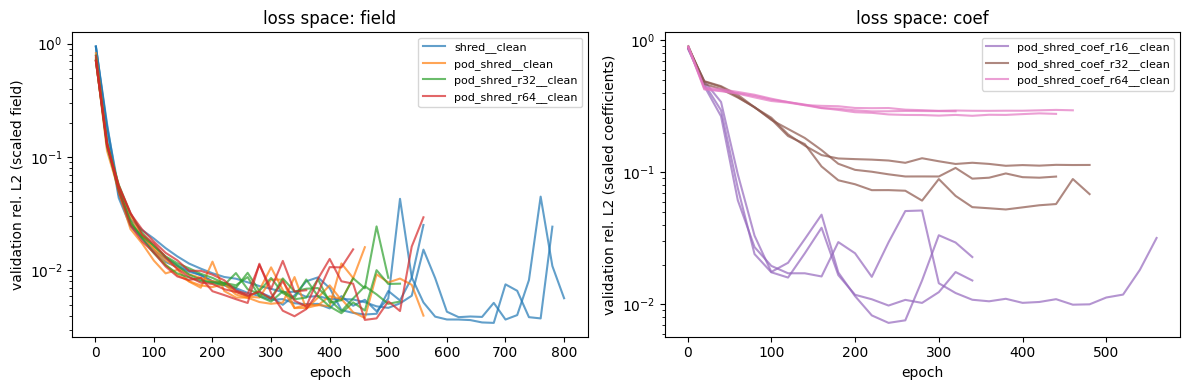

In [5]:
res = load_results(MAIN)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, space in zip(axes, ("field", "coef")):
    for i, run in enumerate(RUNS):
        if describe(run)[2] != space:
            continue
        for s in cfg.eval.seeds:
            if (run, s) not in res:
                continue
            h = load_arrays(MAIN, run, s)["val_history"]
            ax.semilogy(np.r_[1, 20 * np.arange(1, len(h))], h, color=f"C{i}", alpha=0.7,
                        label=run if s == cfg.eval.seeds[0] else None)
    ax.set(xlabel="epoch", ylabel="validation rel. L2 (" + ("scaled field" if space == "field" else "scaled coefficients") + ")",
           title=f"loss space: {space}")
    ax.legend(fontsize=8)
plt.tight_layout()

**Conclusion (tentative).** Predicting POD coefficients with the loss on the decoded field is ≈ 3× cheaper per run and
≈ 20 % less accurate than SHRED's full-field output (0.0025 vs 0.0021, about one seed std apart); rank barely matters
because the Nektar wake is nearly exactly rank ≤ 32 per field. With the paper's loss (MinMax-scaled coefficients), the
accuracy depends strongly on the rank: at r = 16 it matches the field loss, but every extra mode beyond the flow's real
rank carries almost no energy and is still scaled to [0, 1], so it weighs as much in the loss as the dominant modes,
and the energetic modes are underfit (train error 0.018 at r = 64). That weighting is a property of the paper's pipeline,
and it is most harmful here because the data are so low-rank; on richer data (their HYDRO, SST) the extra modes carry
real signal. Speed rankings: the output layer, not the encoder, sets SHRED's cost per epoch on this setup. Clean data
only; robustness to faults is not tested.